In [1]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.stats as stats

In [2]:
ctc = sc.read_h5ad('/mnt/c/Users/ouyangkang/Desktop/ctc_with_anno.h5ad')

In [3]:
ctc_index = ctc.obs[ctc.obs['anno_ctc'] == 'True CTC'].index
ctc = ctc[ctc_index, :]

In [4]:
# exclude negative sample
negative_sample = ['A04086G3', 'C03427D3', 'A04230E2', 'A04230E4_16', 'A04224E3']
positive_index = ctc.obs[~ctc.obs['chip_id'].isin(negative_sample)].index
ctc = ctc[positive_index, :]

In [5]:
sc.pp.filter_genes(ctc, min_cells=1)

/home/ouyangkang/software/miniconda3/envs/sc/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:275: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["n_cells"] = number


In [6]:
ctc

AnnData object with n_obs × n_vars = 261 × 21692
    obs: 'total_counts', 'pct_counts_mt', 'pct_counts_rb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'chip_id', 'patient_info', 'phage_info', '_scvi_batch', '_scvi_labels', 'leiden', 'anno', 'chip_color', 'anno_ctc'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'anno_colors', 'anno_ctc_colors', 'chip_id_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [9]:
sc.pp.neighbors(ctc, use_rep='X_scVI')
sc.tl.leiden(ctc, flavor='igraph', n_iterations=-1)

sc.tl.umap(ctc, min_dist=0.3, spread=1.75)

/home/ouyangkang/software/miniconda3/envs/sc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


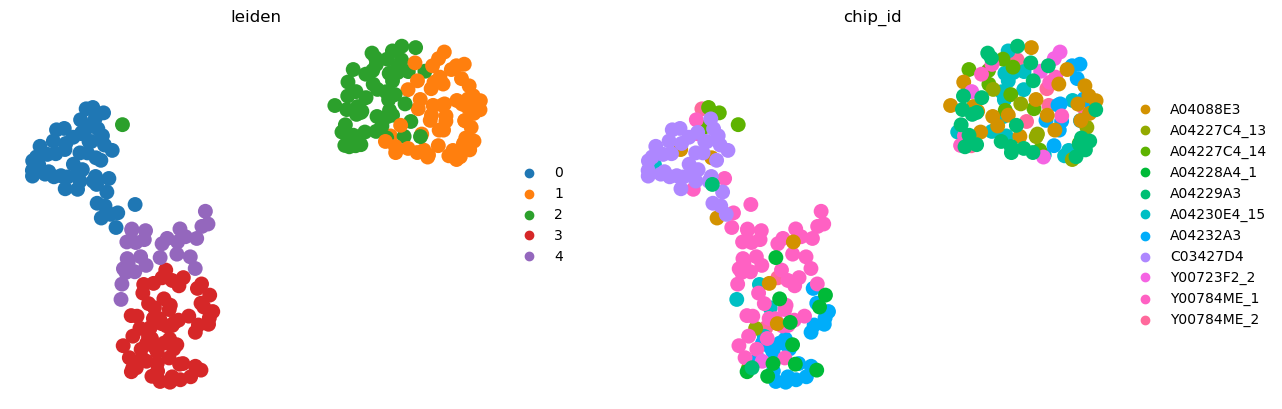

In [10]:
sc.pl.umap(ctc, color=["leiden", 'chip_id'], frameon=False)

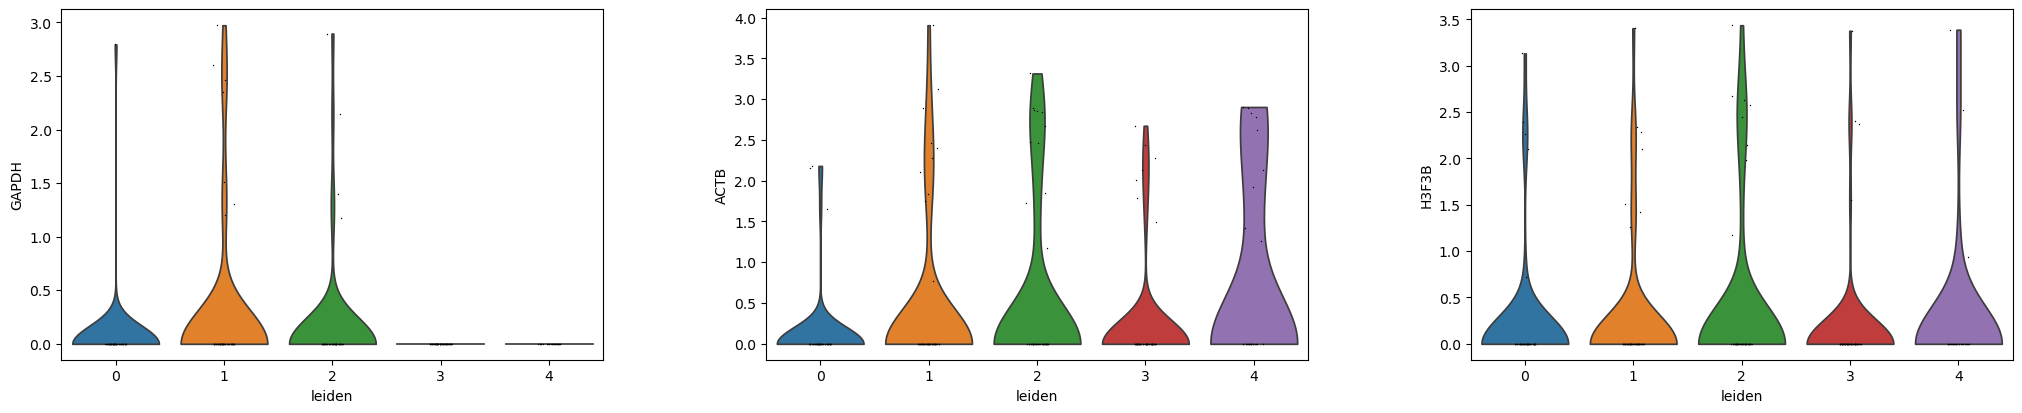

In [11]:
sc.pl.violin(ctc, ['GAPDH', 'ACTB', 'H3F3B'], multi_panel=True, groupby='leiden')

<Axes: >

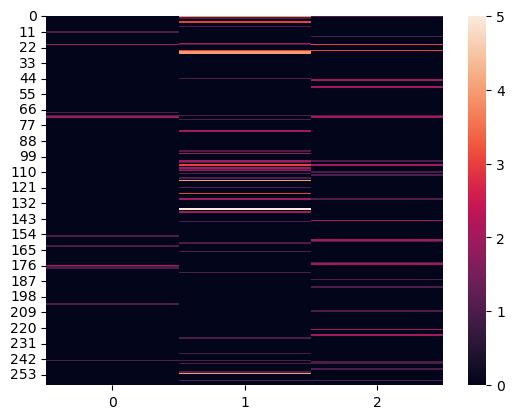

In [ ]:
sns.heatmap(ctc[:, ['GAPDH', 'ACTB', 'H3F3B']].X.todense())

In [27]:
marker_gene = ['EPCAM', 'CDH1', 'KRT8', 'KRT19', 'KRT5', 'KRT14', # epithelial
               'VCAM1', 'ITGAV', 'ITGB3', 'SP1', 'ZEB2', 'SPARC', # mesenchymal
               'ALDH1A1', 'ALDH1A2', 'ANPEP', 'CD44', 'PROM1', 'LGR5', 'ITGA2', 'KLF5', 'MYC', # stem
               'MKI67', 'BIRC5', 'AURKA', 'MYBL2', 'CCNB1', 'CCND1'] # proliferative

In [28]:
marker_gene = [i for i in marker_gene if i in ctc.var_names]

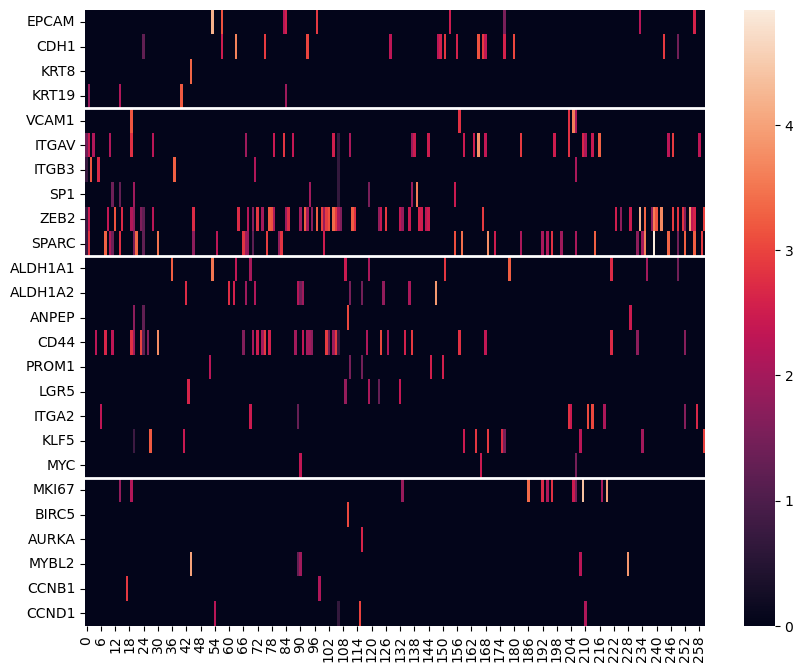

In [41]:
plot_df = pd.DataFrame(ctc[:, marker_gene].X.todense(), columns=marker_gene)

plt.figure(figsize=(10, 8))
sns.heatmap(plot_df.T)

group_boundaries = [4, 10, 19]
for boundary in group_boundaries:
    plt.axhline(y=boundary, color='white', linewidth=2)  # 水平分隔线
    #plt.axvline(x=boundary, color='white', linewidth=2)  # 垂直分隔线

plt.show()